# 04 — Climate Data Exploration

## Machine Learning-Based Early Warning System for Poultry Disease Outbreaks in Nigeria

### Purpose

This notebook explores the climate datasets prepared for integration with the WAHIS poultry
disease surveillance data.

The available climate data include:

- ADM1-level monthly climate data for 2019–2025
- ADM1-level semester climate data for 2019–2025
- a climate-data quality audit
- a Newcastle disease climate-integration dataset

The main objective is to determine whether the climate data are sufficiently complete,
geographically consistent, temporally aligned, and suitable for integration with the
WAHIS analytical table.

### Key questions

1. What climate variables are available?
2. What geographic level is represented?
3. What years are covered?
4. What temporal resolution is available?
5. Are the ADM1 geographic identifiers consistent?
6. Are there missing or duplicated observations?
7. What measurement units are used?
8. How are monthly observations aggregated into semesters?
9. Does the semester-level climate data align with the WAHIS Year + Semester structure?
10. Are there any data-quality limitations that must be addressed before integration?

### Methodological principle

Climate observations must not be treated as equivalent to disease observations.

Missing climate measurements remain missing unless a documented and validated procedure is
used to address them.

Likewise, spatial and temporal aggregation must be explicitly documented rather than
silently assumed.

### Expected outcome

This notebook will establish whether the prepared climate datasets are ready for integration
with the WAHIS analytical table in Notebook 05.

In [4]:
# ============================================================
# CELL 2 — Load Prepared Climate Datasets
# Notebook: 04_Climate_Data_Exploration.ipynb
# ============================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Determine the project root.
# ------------------------------------------------------------
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# ------------------------------------------------------------
# Define the actual locations of the prepared climate files.
# These paths are based on the project structure identified
# during the diagnostic check.
# ------------------------------------------------------------
CLIMATE_DIR = PROJECT_ROOT / "data" / "interim" / "climate"

MONTHLY_CLIMATE_FILE = (
    CLIMATE_DIR / "adm1_monthly_climate_2019_2025.csv"
)

SEMESTER_CLIMATE_FILE = (
    CLIMATE_DIR / "adm1_semester_climate_2019_2025.csv"
)

QUALITY_AUDIT_FILE = (
    CLIMATE_DIR / "climate_quality_audit.csv"
)

NEWCASTLE_INTEGRATION_FILE = (
    PROJECT_ROOT / "data" / "interim" / "newcastle_climate_integration.csv"
)

print("=" * 60)
print("CLIMATE DATA EXPLORATION")
print("=" * 60)

print(f"Project root: {PROJECT_ROOT}")
print(f"Climate directory: {CLIMATE_DIR}")

# ------------------------------------------------------------
# Verify that the expected files exist before loading them.
# ------------------------------------------------------------
expected_files = {
    "Monthly ADM1 climate": MONTHLY_CLIMATE_FILE,
    "Semester ADM1 climate": SEMESTER_CLIMATE_FILE,
    "Climate quality audit": QUALITY_AUDIT_FILE,
    "Newcastle climate integration": NEWCASTLE_INTEGRATION_FILE
}

print("\nFile availability:")

for name, file_path in expected_files.items():
    print(
        f"{name}: "
        f"{'FOUND' if file_path.exists() else 'NOT FOUND'}"
    )

# ------------------------------------------------------------
# Load the datasets that exist.
# ------------------------------------------------------------
climate_datasets = {}

if MONTHLY_CLIMATE_FILE.exists():
    climate_datasets["monthly"] = pd.read_csv(
        MONTHLY_CLIMATE_FILE
    )

if SEMESTER_CLIMATE_FILE.exists():
    climate_datasets["semester"] = pd.read_csv(
        SEMESTER_CLIMATE_FILE
    )

if QUALITY_AUDIT_FILE.exists():
    climate_datasets["quality_audit"] = pd.read_csv(
        QUALITY_AUDIT_FILE
    )

if NEWCASTLE_INTEGRATION_FILE.exists():
    climate_datasets["newcastle_integration"] = pd.read_csv(
        NEWCASTLE_INTEGRATION_FILE
    )

print("\nDatasets loaded:")

for name, df in climate_datasets.items():
    print(
        f"  - {name}: "
        f"{df.shape[0]:,} rows × {df.shape[1]} columns"
    )

CLIMATE DATA EXPLORATION
Project root: c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria
Climate directory: c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\data\interim\climate

File availability:
Monthly ADM1 climate: FOUND
Semester ADM1 climate: FOUND
Climate quality audit: FOUND
Newcastle climate integration: FOUND

Datasets loaded:
  - monthly: 3,108 rows × 12 columns
  - semester: 518 rows × 13 columns
  - quality_audit: 1 rows × 13 columns
  - newcastle_integration: 255 rows × 19 columns


In [5]:
# ============================================================
# CELL 3 — Climate Dataset Structure and Quality Audit
# Notebook: 04_Climate_Data_Exploration.ipynb
# ============================================================

# ------------------------------------------------------------
# Inspect every loaded climate dataset.
# ------------------------------------------------------------

for dataset_name, df in climate_datasets.items():

    print("\n" + "=" * 70)
    print(f"DATASET: {dataset_name.upper()}")
    print("=" * 70)

    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]:,}")

    print("\nColumns:")
    for column in df.columns:
        print(f"  - {column}")

    print("\nData types:")
    display(df.dtypes.to_frame("dtype"))

    print("\nFirst five records:")
    display(df.head())

    # --------------------------------------------------------
    # Missingness audit.
    # --------------------------------------------------------
    missing_audit = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percentage": (
            df.isna().mean() * 100
        ).round(2)
    })

    print("\nMissing-value audit:")
    display(
        missing_audit.sort_values(
            "missing_count",
            ascending=False
        )
    )

    print(
        "\nDuplicate complete rows:",
        df.duplicated().sum()
    )


DATASET: MONTHLY
Rows: 3,108
Columns: 12

Columns:
  - administrative_division
  - year
  - month
  - date
  - temperature_c_valid_weight
  - temperature_c
  - dewpoint_c_valid_weight
  - dewpoint_c
  - precipitation_monthly_total_mm_valid_weight
  - precipitation_monthly_total_mm
  - wind_speed_from_mean_components_ms_valid_weight
  - wind_speed_from_mean_components_ms

Data types:


,dtype
administrative_division,object
year,int64
month,int64
date,object
temperature_c_valid_weight,float64
temperature_c,float64
dewpoint_c_valid_weight,float64
dewpoint_c,float64
precipitation_monthly_total_mm_valid_weight,float64
precipitation_monthly_total_mm,float64



First five records:


,administrative_division,year,month,date,temperature_c_valid_weight,temperature_c,dewpoint_c_valid_weight,dewpoint_c,precipitation_monthly_total_mm_valid_weight,precipitation_monthly_total_mm,wind_speed_from_mean_components_ms_valid_weight,wind_speed_from_mean_components_ms
0,Abia,2019,1,2019-01-01,1.0,28.290363,1.0,21.244714,1.0,43.712418,1.0,0.967520
1,Abia,2019,2,2019-02-01,1.0,28.180683,1.0,21.914398,1.0,62.313286,1.0,0.835261
2,Abia,2019,3,2019-03-01,1.0,27.115433,1.0,23.783841,1.0,126.147962,1.0,1.421936
3,Abia,2019,4,2019-04-01,1.0,27.235517,1.0,24.272288,1.0,170.561159,1.0,1.361169
4,Abia,2019,5,2019-05-01,1.0,26.310992,1.0,23.984177,1.0,279.261814,1.0,1.084655



Missing-value audit:


,missing_count,missing_percentage
administrative_division,0,0.0
year,0,0.0
month,0,0.0
date,0,0.0
temperature_c_valid_weight,0,0.0
temperature_c,0,0.0
dewpoint_c_valid_weight,0,0.0
dewpoint_c,0,0.0
precipitation_monthly_total_mm_valid_weight,0,0.0
precipitation_monthly_total_mm,0,0.0


... (15 outputs left out)

,standard_adm1_name,year,semester,source_record_count,outbreak_count_observed,reported_outbreaks,outbreak_count_available,administrative_division,period,months_observed,temperature_c,dewpoint_c,semester_total_precipitation_mm,semester_mean_wind_component_magnitude_ms,minimum_temperature_c_spatial_coverage,minimum_dewpoint_c_spatial_coverage,minimum_precipitation_monthly_total_mm_spatial_coverage,minimum_wind_speed_from_mean_components_ms_spatial_coverage,_merge
0,Abia,2020,Jul-Dec,2,1,1.0,True,Abia,Jul-Dec 2020,6,25.599192,22.463069,1091.109333,1.169023,1.0,1.0,1.0,1.0,both
1,Abia,2021,Jan-Jun,2,1,4.0,True,Abia,Jan-Jun 2021,6,27.652334,22.147942,599.798555,1.176361,1.0,1.0,1.0,1.0,both
2,Abia,2021,Jul-Dec,2,1,9.0,True,Abia,Jul-Dec 2021,6,25.498136,22.369064,1417.637608,0.969542,1.0,1.0,1.0,1.0,both
3,Abia,2022,Jan-Jun,2,1,8.0,True,Abia,Jan-Jun 2022,6,27.335367,21.532264,632.624339,1.061308,1.0,1.0,1.0,1.0,both
4,Abia,2022,Jul-Dec,2,1,3.0,True,Abia,Jul-Dec 2022,6,25.573137,21.824683,800.634701,1.049461,1.0,1.0,1.0,1.0,both



Missing-value audit:


,missing_count,missing_percentage
reported_outbreaks,5,1.96
year,0,0.00
standard_adm1_name,0,0.00
semester,0,0.00
source_record_count,0,0.00
outbreak_count_observed,0,0.00
outbreak_count_available,0,0.00
administrative_division,0,0.00
period,0,0.00
months_observed,0,0.00



Duplicate complete rows: 0


In [6]:
# ============================================================
# CELL 4 — Geographic and Temporal Coverage
# Notebook: 04_Climate_Data_Exploration.ipynb
# ============================================================

# ------------------------------------------------------------
# Explore geographic and temporal fields in each climate
# dataset.
#
# We inspect the actual column names instead of assuming
# their names.
# ------------------------------------------------------------

for dataset_name in ["monthly", "semester"]:

    if dataset_name not in climate_datasets:
        continue

    df = climate_datasets[dataset_name]

    print("\n" + "=" * 70)
    print(f"{dataset_name.upper()} CLIMATE COVERAGE")
    print("=" * 70)

    print("\nPotential geographic columns:")

    geographic_candidates = [
        column
        for column in df.columns
        if any(
            keyword in str(column).lower()
            for keyword in [
                "admin",
                "adm1",
                "state",
                "region",
                "location",
                "province"
            ]
        )
    ]

    print(geographic_candidates)

    print("\nPotential temporal columns:")

    temporal_candidates = [
        column
        for column in df.columns
        if any(
            keyword in str(column).lower()
            for keyword in [
                "year",
                "month",
                "semester",
                "date",
                "period"
            ]
        )
    ]

    print(temporal_candidates)

    # --------------------------------------------------------
    # Inspect unique values and ranges for candidate fields.
    # --------------------------------------------------------
    for column in geographic_candidates:

        print(f"\nGeographic field: {column}")
        print(
            "Unique values:",
            df[column].nunique(dropna=True)
        )
        print(
            "Missing values:",
            df[column].isna().sum()
        )

        display(
            df[column]
            .value_counts(dropna=False)
            .head(50)
            .to_frame("records")
        )

    for column in temporal_candidates:

        print(f"\nTemporal field: {column}")

        print(
            "Data type:",
            df[column].dtype
        )

        print(
            "Unique values:",
            df[column].nunique(dropna=True)
        )

        display(
            df[column]
            .value_counts(dropna=False)
            .sort_index()
            .head(50)
            .to_frame("records")
        )


MONTHLY CLIMATE COVERAGE

Potential geographic columns:
['administrative_division']

Potential temporal columns:
['year', 'month', 'date', 'precipitation_monthly_total_mm_valid_weight', 'precipitation_monthly_total_mm']

Geographic field: administrative_division
Unique values: 37
Missing values: 0


,records
administrative_division,
Abia,84
Abuja Federal Capital Territory,84
Adamawa,84
Akwa Ibom,84
Anambra,84
Bauchi,84
Bayelsa,84
Benue,84
Borno,84



Temporal field: year
Data type: int64
Unique values: 7


,records
year,
2019,444
2020,444
2021,444
2022,444
2023,444
2024,444
2025,444



Temporal field: month
Data type: int64
Unique values: 12


,records
month,
1,259
2,259
3,259
4,259
5,259
6,259
7,259
8,259
9,259


... (18 outputs left out)


Temporal field: semester_mean_wind_component_magnitude_ms
Data type: float64
Unique values: 518


,records
semester_mean_wind_component_magnitude_ms,
0.749050,1
0.749571,1
0.757027,1
0.759427,1
0.792166,1
0.832585,1
0.884409,1
0.884770,1
0.898763,1



Temporal field: minimum_precipitation_monthly_total_mm_spatial_coverage
Data type: float64
Unique values: 35


,records
minimum_precipitation_monthly_total_mm_spatial_coverage,
0.821991,14
0.956014,14
0.965651,14
0.976071,14
0.984152,14
0.996428,14
0.997074,14
0.998046,14
1.000000,14


In [7]:
# ============================================================
# CELL 5 — Climate Variable Audit
# Notebook: 04_Climate_Data_Exploration.ipynb
# ============================================================

# ------------------------------------------------------------
# Identify numeric variables in the monthly and semester
# climate datasets.
#
# These variables are potential predictors, but their actual
# interpretation and units must be confirmed from the source
# data and quality documentation.
# ------------------------------------------------------------

for dataset_name in ["monthly", "semester"]:

    if dataset_name not in climate_datasets:
        continue

    df = climate_datasets[dataset_name]

    print("\n" + "=" * 70)
    print(f"{dataset_name.upper()} CLIMATE VARIABLES")
    print("=" * 70)

    numeric_columns = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    print(
        f"Numeric columns detected: "
        f"{len(numeric_columns)}"
    )

    if numeric_columns:

        numeric_summary = df[numeric_columns].describe().T

        numeric_summary["missing_count"] = (
            df[numeric_columns].isna().sum()
        )

        numeric_summary["missing_percentage"] = (
            df[numeric_columns].isna().mean() * 100
        ).round(2)

        display(numeric_summary)

    # --------------------------------------------------------
    # Display non-numeric fields separately.
    # --------------------------------------------------------
    categorical_columns = [
        column
        for column in df.columns
        if column not in numeric_columns
    ]

    print("\nNon-numeric columns:")
    print(categorical_columns)


MONTHLY CLIMATE VARIABLES
Numeric columns detected: 10


,count,mean,std,min,25%,50%,75%,max,missing_count,missing_percentage
year,3108.0,2022.000000,2.000322,2019.000000,2020.000000,2022.000000,2024.000000,2025.000000,0,0.0
month,3108.0,6.500000,3.452608,1.000000,3.750000,6.500000,9.250000,12.000000,0,0.0
temperature_c_valid_weight,3108.0,0.991768,0.029934,0.821991,1.000000,1.000000,1.000000,1.000000,0,0.0
temperature_c,3108.0,27.143430,2.388035,20.397389,25.335261,26.975487,28.573587,34.915216,0,0.0
dewpoint_c_valid_weight,3108.0,0.991768,0.029934,0.821991,1.000000,1.000000,1.000000,1.000000,0,0.0
dewpoint_c,3108.0,17.460858,7.869470,-7.876288,14.395878,21.382261,22.712103,25.543319,0,0.0
precipitation_monthly_total_mm_valid_weight,3108.0,0.991768,0.029934,0.821991,1.000000,1.000000,1.000000,1.000000,0,0.0
precipitation_monthly_total_mm,3108.0,97.839732,111.380749,0.009673,3.677912,54.223135,166.512833,705.217658,0,0.0
wind_speed_from_mean_components_ms_valid_weight,3108.0,0.991768,0.029934,0.821991,1.000000,1.000000,1.000000,1.000000,0,0.0
wind_speed_from_mean_components_ms,3108.0,1.522648,0.669429,0.175432,1.036521,1.467872,1.905853,3.763025,0,0.0



Non-numeric columns:
['administrative_division', 'date']

SEMESTER CLIMATE VARIABLES
Numeric columns detected: 10


,count,mean,std,min,25%,50%,75%,max,missing_count,missing_percentage
year,518.0,2022.000000,2.001933,2019.000000,2020.000000,2022.000000,2024.000000,2025.000000,0,0.0
months_observed,518.0,6.000000,0.000000,6.000000,6.000000,6.000000,6.000000,6.000000,0,0.0
temperature_c,518.0,27.143430,1.548100,23.775282,25.927693,27.001964,28.252277,31.256720,0,0.0
dewpoint_c,518.0,17.460858,5.463660,3.092163,14.793636,18.870491,22.023362,24.791192,0,0.0
semester_total_precipitation_mm,518.0,587.038393,415.254842,8.321334,233.905712,564.675880,814.050213,2295.312971,0,0.0
semester_mean_wind_component_magnitude_ms,518.0,1.522648,0.409193,0.749050,1.210337,1.417866,1.845789,2.746059,0,0.0
minimum_temperature_c_spatial_coverage,518.0,0.991768,0.029958,0.821991,1.000000,1.000000,1.000000,1.000000,0,0.0
minimum_dewpoint_c_spatial_coverage,518.0,0.991768,0.029958,0.821991,1.000000,1.000000,1.000000,1.000000,0,0.0
minimum_precipitation_monthly_total_mm_spatial_coverage,518.0,0.991768,0.029958,0.821991,1.000000,1.000000,1.000000,1.000000,0,0.0
minimum_wind_speed_from_mean_components_ms_spatial_coverage,518.0,0.991768,0.029958,0.821991,1.000000,1.000000,1.000000,1.000000,0,0.0



Non-numeric columns:
['administrative_division', 'semester', 'period']


In [8]:
# ============================================================
# CELL 6 — Monthly and Semester Temporal Alignment
# Notebook: 04_Climate_Data_Exploration.ipynb
# ============================================================

# ------------------------------------------------------------
# Compare the temporal structure of the monthly and semester
# climate datasets.
#
# The objective is to establish whether the semester climate
# dataset provides the appropriate temporal representation
# for integration with the WAHIS semester-based surveillance
# records.
# ------------------------------------------------------------

monthly_df = climate_datasets.get("monthly")
semester_df = climate_datasets.get("semester")

if monthly_df is None or semester_df is None:

    print(
        "Both monthly and semester climate datasets "
        "are required for this comparison."
    )

else:

    print("=" * 70)
    print("MONTHLY CLIMATE DATA")
    print("=" * 70)

    print(
        f"Rows: {len(monthly_df):,}"
    )

    print("\nColumns:")
    print(monthly_df.columns.tolist())

    print("\n" + "=" * 70)
    print("SEMESTER CLIMATE DATA")
    print("=" * 70)

    print(
        f"Rows: {len(semester_df):,}"
    )

    print("\nColumns:")
    print(semester_df.columns.tolist())

    # --------------------------------------------------------
    # Display likely year/period fields.
    # --------------------------------------------------------
    for name, df in [
        ("Monthly", monthly_df),
        ("Semester", semester_df)
    ]:

        print("\n" + "-" * 50)
        print(f"{name} temporal fields")

        temporal_columns = [
            column
            for column in df.columns
            if any(
                keyword in str(column).lower()
                for keyword in [
                    "year",
                    "month",
                    "semester",
                    "period"
                ]
            )
        ]

        for column in temporal_columns:

            print(f"\n{column}")
            print(
                df[column]
                .value_counts(dropna=False)
                .sort_index()
                .head(100)
            )

MONTHLY CLIMATE DATA
Rows: 3,108

Columns:
['administrative_division', 'year', 'month', 'date', 'temperature_c_valid_weight', 'temperature_c', 'dewpoint_c_valid_weight', 'dewpoint_c', 'precipitation_monthly_total_mm_valid_weight', 'precipitation_monthly_total_mm', 'wind_speed_from_mean_components_ms_valid_weight', 'wind_speed_from_mean_components_ms']

SEMESTER CLIMATE DATA
Rows: 518

Columns:
['administrative_division', 'year', 'semester', 'period', 'months_observed', 'temperature_c', 'dewpoint_c', 'semester_total_precipitation_mm', 'semester_mean_wind_component_magnitude_ms', 'minimum_temperature_c_spatial_coverage', 'minimum_dewpoint_c_spatial_coverage', 'minimum_precipitation_monthly_total_mm_spatial_coverage', 'minimum_wind_speed_from_mean_components_ms_spatial_coverage']

--------------------------------------------------
Monthly temporal fields

year
year
2019    444
2020    444
2021    444
2022    444
2023    444
2024    444
2025    444
Name: count, dtype: int64

month
month
1 

In [9]:
# ============================================================
# CELL 7 — Climate ADM1 Geographic Consistency Check
# Notebook: 04_Climate_Data_Exploration.ipynb
# ============================================================

# ------------------------------------------------------------
# Load the validated WAHIS ADM1 boundary lookup produced by
# Notebook 03.
# ------------------------------------------------------------

BOUNDARY_LOOKUP_FILE = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "wahis_administrative_boundary_lookup.csv"
)

print("=" * 70)
print("ADMINISTRATIVE BOUNDARY CONSISTENCY CHECK")
print("=" * 70)

if not BOUNDARY_LOOKUP_FILE.exists():

    print(
        "WARNING: The validated WAHIS administrative-boundary "
        "lookup was not found."
    )

else:

    boundary_lookup = pd.read_csv(
        BOUNDARY_LOOKUP_FILE
    )

    print(
        f"Boundary lookup rows: "
        f"{len(boundary_lookup):,}"
    )

    print("\nBoundary lookup columns:")
    print(boundary_lookup.columns.tolist())

    display(boundary_lookup.head())

    # --------------------------------------------------------
    # Identify likely standardised ADM1 fields.
    # --------------------------------------------------------
    lookup_candidates = [
        column
        for column in boundary_lookup.columns
        if any(
            keyword in str(column).lower()
            for keyword in [
                "admin",
                "adm1",
                "name",
                "boundary"
            ]
        )
    ]

    print("\nPotential ADM1/name fields:")
    print(lookup_candidates)

    # --------------------------------------------------------
    # Inspect the climate ADM1 values.
    # --------------------------------------------------------
    for dataset_name in ["monthly", "semester"]:

        if dataset_name not in climate_datasets:
            continue

        df = climate_datasets[dataset_name]

        climate_geo_candidates = [
            column
            for column in df.columns
            if any(
                keyword in str(column).lower()
                for keyword in [
                    "admin",
                    "adm1",
                    "state",
                    "region"
                ]
            )
        ]

        print("\n" + "-" * 60)
        print(
            f"{dataset_name.upper()} CLIMATE GEOGRAPHIC FIELDS"
        )
        print("-" * 60)

        print(climate_geo_candidates)

        for column in climate_geo_candidates:

            print(f"\nField: {column}")

            print(
                "Unique geographic values:",
                df[column].nunique(dropna=True)
            )

            display(
                df[column]
                .value_counts(dropna=False)
                .head(50)
                .to_frame("records")
            )

ADMINISTRATIVE BOUNDARY CONSISTENCY CHECK
Boundary lookup rows: 39

Boundary lookup columns:
['administrative_division', 'admin_division_standard', 'validated_boundary_name', 'geographic_level', 'boundary_match', 'geographic_match_status', 'validation_note']


,administrative_division,admin_division_standard,validated_boundary_name,geographic_level,boundary_match,geographic_match_status,validation_note
0,Abia,abia,Abia,ADM1,True,Matched,Standard ADM1 geographic match
1,Adamawa,adamawa,Adamawa,ADM1,True,Matched,Standard ADM1 geographic match
2,Akwa Ibom,akwa ibom,Akwa Ibom,ADM1,True,Matched,Standard ADM1 geographic match
3,Anambra,anambra,Anambra,ADM1,True,Matched,Standard ADM1 geographic match
4,Bauchi,bauchi,Bauchi,ADM1,True,Matched,Standard ADM1 geographic match



Potential ADM1/name fields:
['administrative_division', 'admin_division_standard', 'validated_boundary_name', 'boundary_match']

------------------------------------------------------------
MONTHLY CLIMATE GEOGRAPHIC FIELDS
------------------------------------------------------------
['administrative_division']

Field: administrative_division
Unique geographic values: 37


,records
administrative_division,
Abia,84
Abuja Federal Capital Territory,84
Adamawa,84
Akwa Ibom,84
Anambra,84
Bauchi,84
Bayelsa,84
Benue,84
Borno,84



------------------------------------------------------------
SEMESTER CLIMATE GEOGRAPHIC FIELDS
------------------------------------------------------------
['administrative_division']

Field: administrative_division
Unique geographic values: 37


,records
administrative_division,
Abia,14
Abuja Federal Capital Territory,14
Adamawa,14
Akwa Ibom,14
Anambra,14
Bauchi,14
Bayelsa,14
Benue,14
Borno,14


In [10]:
# ============================================================
# CELL 8 — Existing Climate Quality Audit
# Notebook: 04_Climate_Data_Exploration.ipynb
# ============================================================

# ------------------------------------------------------------
# Review the existing climate quality audit.
# ------------------------------------------------------------

quality_audit = climate_datasets.get("quality_audit")

if quality_audit is None:

    print(
        "The climate quality audit file was not loaded."
    )

else:

    print("=" * 70)
    print("EXISTING CLIMATE QUALITY AUDIT")
    print("=" * 70)

    print(
        f"Rows: {quality_audit.shape[0]:,}"
    )

    print(
        f"Columns: {quality_audit.shape[1]:,}"
    )

    print("\nColumns:")
    print(quality_audit.columns.tolist())

    print("\nFirst records:")
    display(quality_audit.head(20))

    print("\nData types:")
    display(
        quality_audit.dtypes.to_frame("dtype")
    )

    print("\nMissing values:")
    display(
        quality_audit.isna()
        .sum()
        .to_frame("missing_count")
    )

EXISTING CLIMATE QUALITY AUDIT
Rows: 1
Columns: 13

Columns:
['monthly_rows', 'expected_monthly_rows', 'monthly_duplicate_keys', 'semester_rows', 'expected_semester_rows', 'semester_duplicate_keys', 'monthly_dewpoint_violations', 'semester_dewpoint_violations', 'negative_monthly_rainfall', 'negative_semester_rainfall', 'negative_wind_proxy', 'all_semester_keys_matched', 'maximum_rainfall_reconciliation_difference_mm']

First records:


,monthly_rows,expected_monthly_rows,monthly_duplicate_keys,semester_rows,expected_semester_rows,semester_duplicate_keys,monthly_dewpoint_violations,semester_dewpoint_violations,negative_monthly_rainfall,negative_semester_rainfall,negative_wind_proxy,all_semester_keys_matched,maximum_rainfall_reconciliation_difference_mm
0,3108,3108,0,518,518,0,0,0,0,0,0,True,6.821210e-13



Data types:


,dtype
monthly_rows,int64
expected_monthly_rows,int64
monthly_duplicate_keys,int64
semester_rows,int64
expected_semester_rows,int64
semester_duplicate_keys,int64
monthly_dewpoint_violations,int64
semester_dewpoint_violations,int64
negative_monthly_rainfall,int64
negative_semester_rainfall,int64



Missing values:


,missing_count
monthly_rows,0
expected_monthly_rows,0
monthly_duplicate_keys,0
semester_rows,0
expected_semester_rows,0
semester_duplicate_keys,0
monthly_dewpoint_violations,0
semester_dewpoint_violations,0
negative_monthly_rainfall,0
negative_semester_rainfall,0



MONTHLY CLIMATE VARIABLE DISTRIBUTIONS


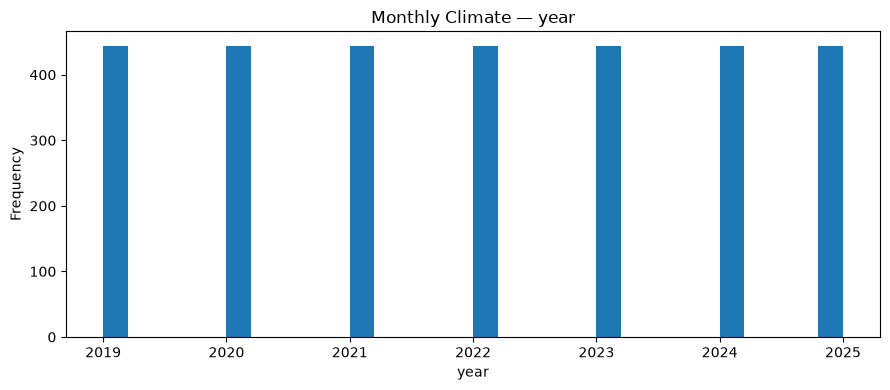

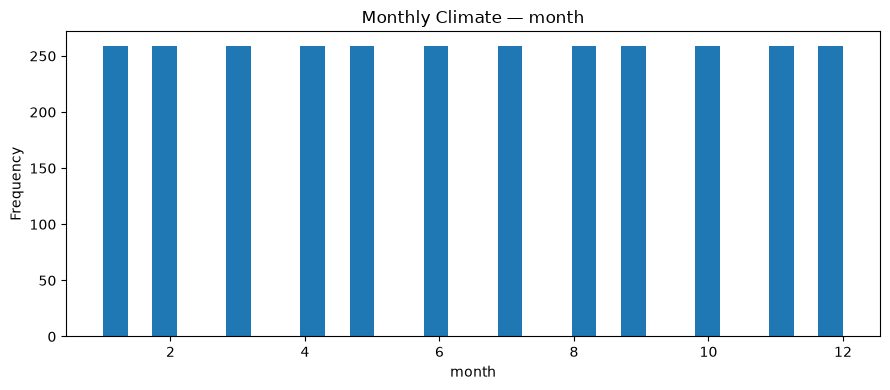

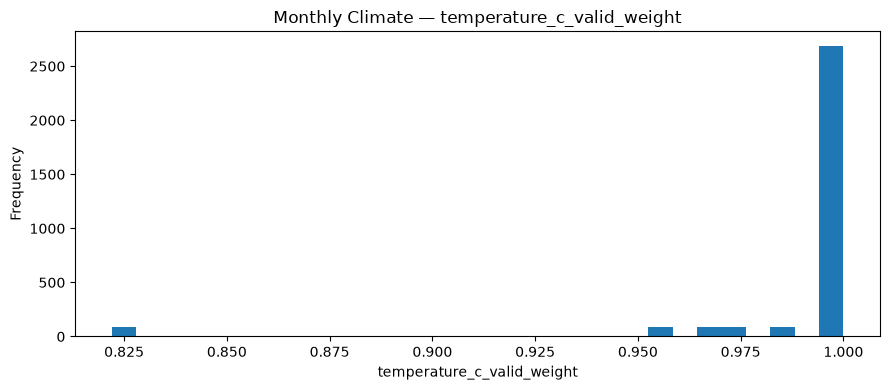

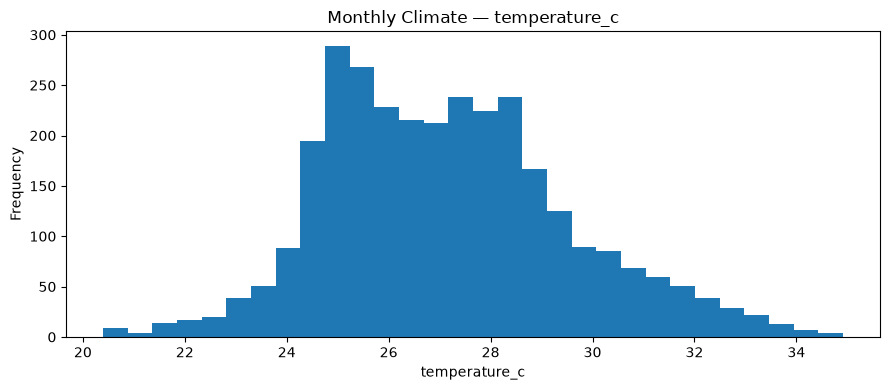

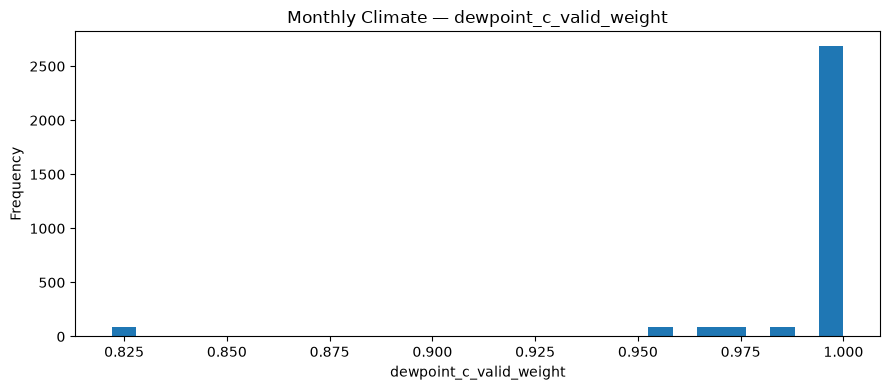

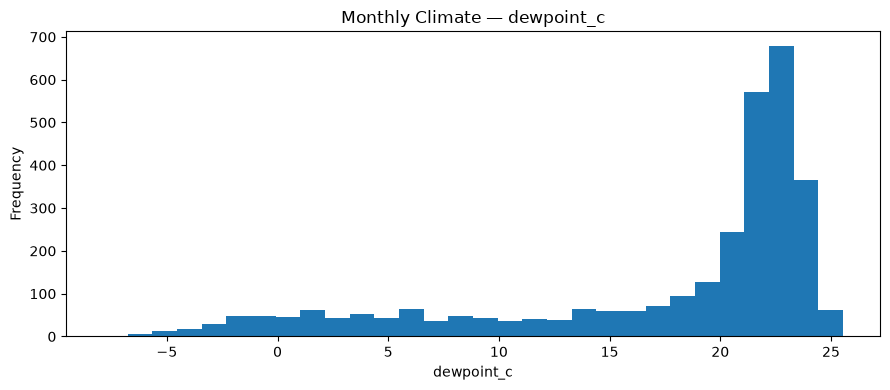

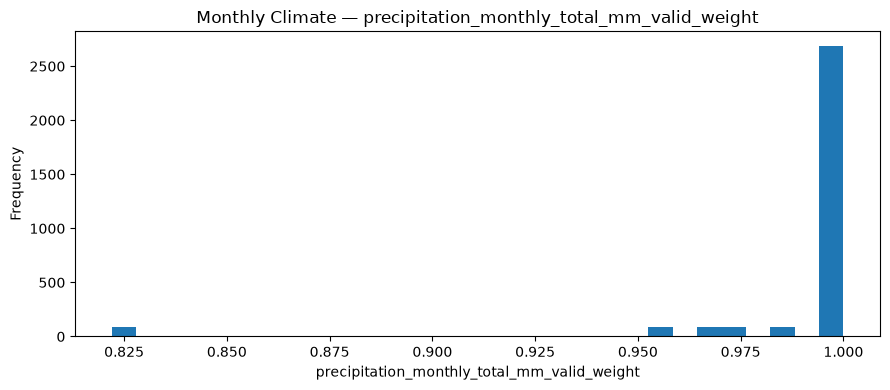

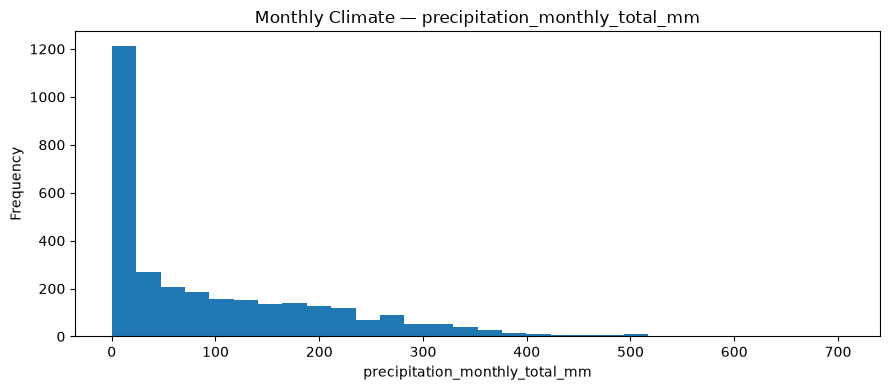

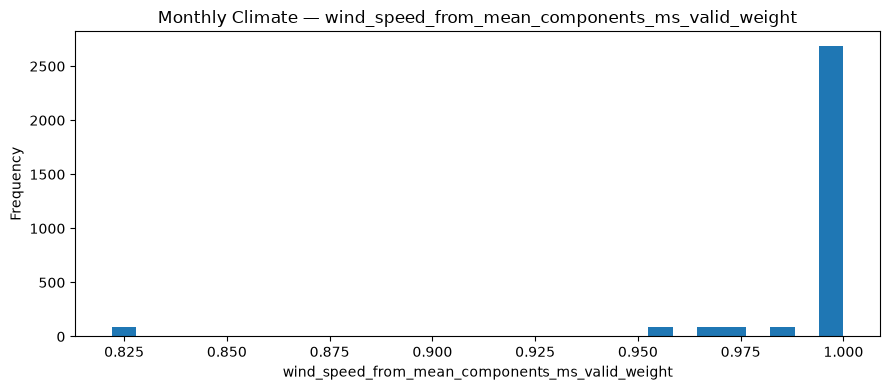

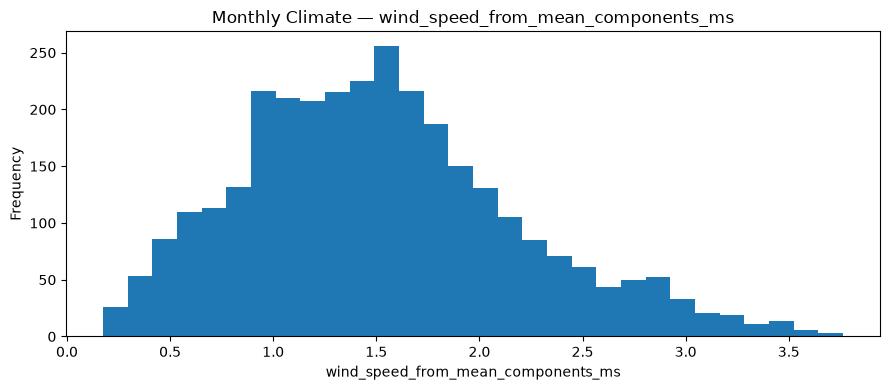


SEMESTER CLIMATE VARIABLE DISTRIBUTIONS


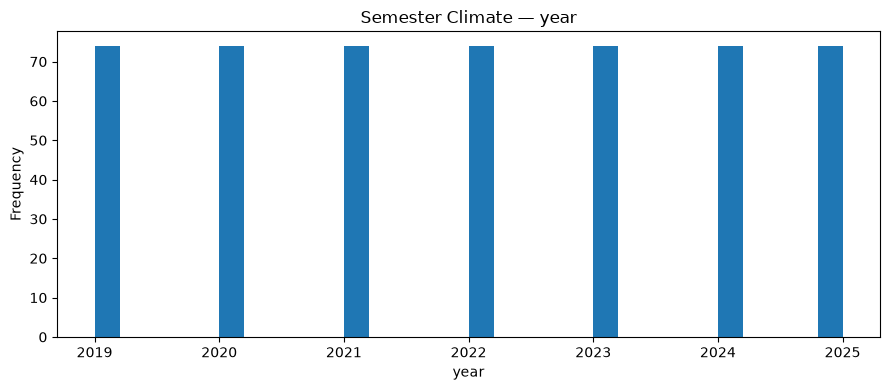

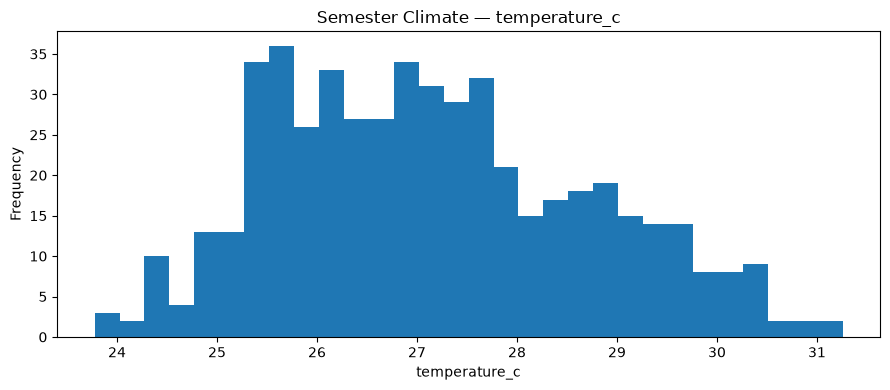

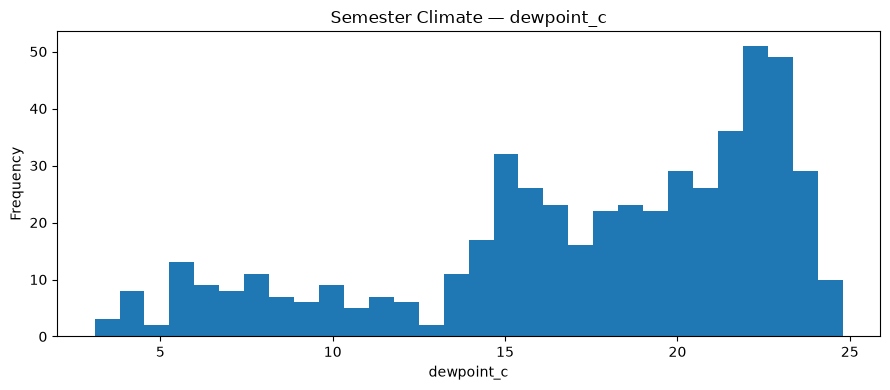

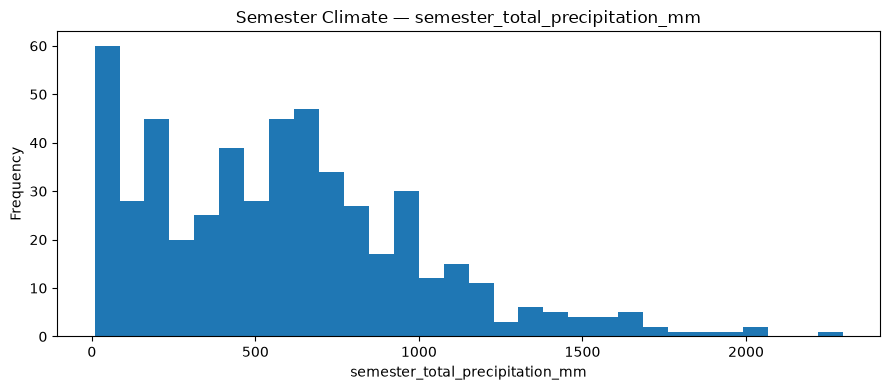

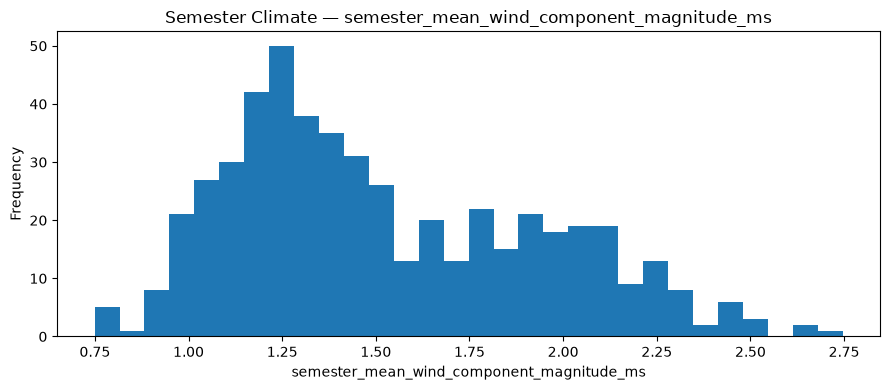

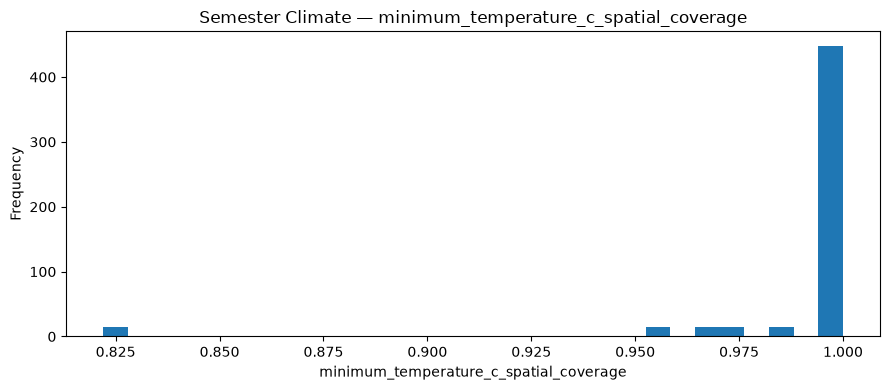

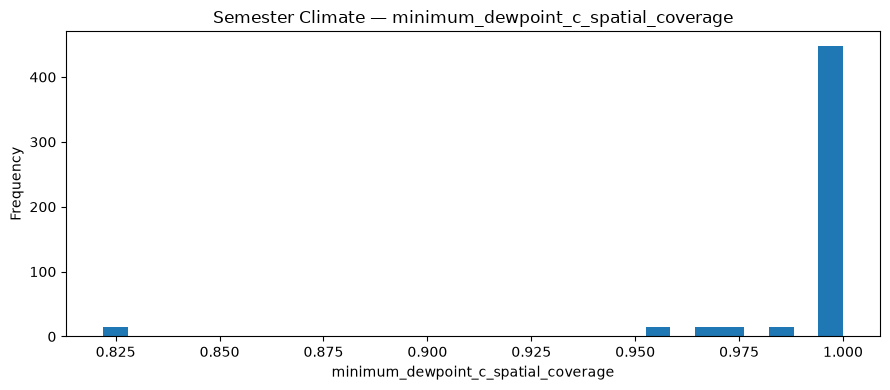

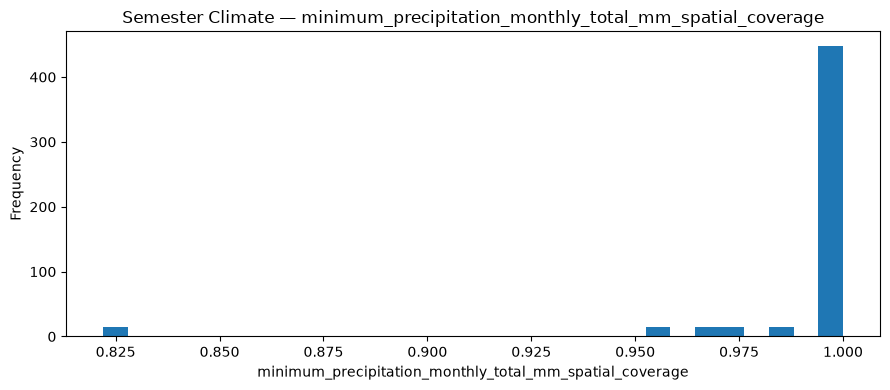

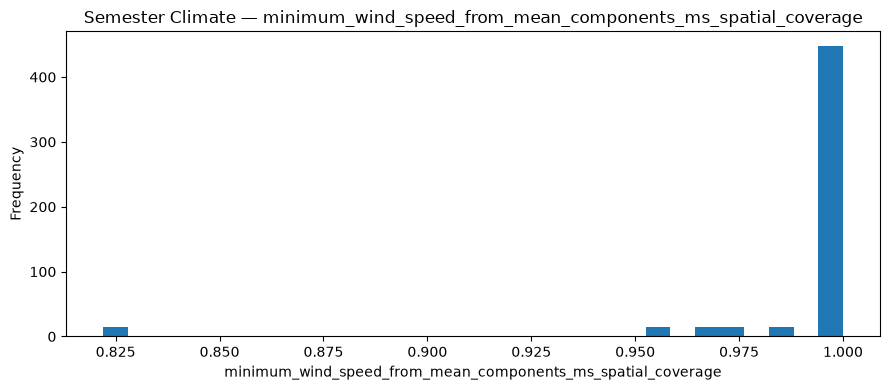

In [11]:
# ============================================================
# CELL 9 — Climate Variable Visual Exploration
# Notebook: 04_Climate_Data_Exploration.ipynb
# ============================================================

# ------------------------------------------------------------
# Generate basic distributions for numeric climate variables.
#
# These plots are exploratory and are not yet used for model
# selection.
# ------------------------------------------------------------

for dataset_name in ["monthly", "semester"]:

    if dataset_name not in climate_datasets:
        continue

    df = climate_datasets[dataset_name]

    numeric_columns = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    print("\n" + "=" * 70)
    print(
        f"{dataset_name.upper()} CLIMATE VARIABLE DISTRIBUTIONS"
    )
    print("=" * 70)

    for column in numeric_columns:

        # Avoid plotting identifier-like numeric fields when
        # they have very few unique values.
        if df[column].nunique(dropna=True) <= 2:
            continue

        values = df[column].dropna()

        if values.empty:
            continue

        plt.figure(figsize=(9, 4))

        plt.hist(
            values,
            bins=30
        )

        plt.title(
            f"{dataset_name.title()} Climate — {column}"
        )

        plt.xlabel(column)
        plt.ylabel("Frequency")

        plt.tight_layout()
        plt.show()

In [12]:
# ============================================================
# CELL 10 — Climate Integration Readiness Assessment
# Notebook: 04_Climate_Data_Exploration.ipynb
# ============================================================

# ------------------------------------------------------------
# Summarise the evidence required before proceeding to
# Notebook 05 — Data Integration.
# ------------------------------------------------------------

monthly_df = climate_datasets.get("monthly")
semester_df = climate_datasets.get("semester")

print("=" * 70)
print("CLIMATE DATA — INTEGRATION READINESS ASSESSMENT")
print("=" * 70)

print("\nAvailable climate datasets:")

for dataset_name, df in climate_datasets.items():
    print(
        f"  - {dataset_name}: "
        f"{df.shape[0]:,} rows × {df.shape[1]} columns"
    )

print("\nKey integration requirements:")
print(
    "1. ADM1 geography must be identifiable and validated."
)
print(
    "2. Climate years must overlap the WAHIS modelling period."
)
print(
    "3. Semester climate data must be compatible with "
    "WAHIS Jan-Jun / Jul-Dec periods."
)
print(
    "4. Climate variables and their units must be understood."
)
print(
    "5. Missing climate observations must remain distinguishable "
    "from measured zero values."
)
print(
    "6. Duplicate spatial-temporal observations must be investigated."
)
print(
    "7. Any geographic name reconciliation must be explicit."
)

# ------------------------------------------------------------
# Basic duplicate checks for the two main datasets.
# ------------------------------------------------------------
for dataset_name, df in [
    ("monthly", monthly_df),
    ("semester", semester_df)
]:

    if df is None:
        continue

    print("\n" + "-" * 60)
    print(f"{dataset_name.upper()} DUPLICATE CHECK")
    print("-" * 60)

    print(
        "Duplicate complete rows:",
        df.duplicated().sum()
    )

print("\n" + "=" * 70)
print("CLIMATE EXPLORATION COMPLETED")
print("=" * 70)

print(
    "\nThe next stage is Notebook 05 — Data Integration."
)

print(
    "\nNotebook 05 should use the validated climate structure "
    "to construct a reproducible spatial-temporal integration "
    "between the WAHIS analytical table and the climate data."
)

CLIMATE DATA — INTEGRATION READINESS ASSESSMENT

Available climate datasets:
  - monthly: 3,108 rows × 12 columns
  - semester: 518 rows × 13 columns
  - quality_audit: 1 rows × 13 columns
  - newcastle_integration: 255 rows × 19 columns

Key integration requirements:
1. ADM1 geography must be identifiable and validated.
2. Climate years must overlap the WAHIS modelling period.
3. Semester climate data must be compatible with WAHIS Jan-Jun / Jul-Dec periods.
4. Climate variables and their units must be understood.
5. Missing climate observations must remain distinguishable from measured zero values.
6. Duplicate spatial-temporal observations must be investigated.
7. Any geographic name reconciliation must be explicit.

------------------------------------------------------------
MONTHLY DUPLICATE CHECK
------------------------------------------------------------
Duplicate complete rows: 0

------------------------------------------------------------
SEMESTER DUPLICATE CHECK
-----------